In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
# import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("/code")
import bg_spatial_plots.plot_spatial_histograms as histplot
from bg_spatial_plots.data_utils import load_anndata_obs
from bg_spatial_plots.figure_utils import add_scalebar
from bg_spatial_plots.coordinate_transforms import get_annotation_coords
from bg_spatial_plots.constants_color_palettes import CURRENT_COLOR_DICT_OF_DICTS
from bg_spatial_plots.utils import GROUP_SHORT_NAMES
from bg_spatial_plots.figure_utils import plot_spatial_subset, format_spatial_axes

%matplotlib inline

In [3]:
group_color_dict = CURRENT_COLOR_DICT_OF_DICTS['Group']
save_figs=False
dpi=600

In [4]:
mac_file = '/data/cirro_files_hmba_macaque_20260811/hmba_release_format_macaque_cirro_h5ad_20260716_newnames_20260811.h5ad'
mac_ad = load_anndata_obs(mac_file, data_structure='adata', qc=True)
mac_transform = '/data/macaque_annotations'

In [5]:
marm_file = '/data/cirro_files_hmba_marmoset_CJ23.56.004_BG_revisions_20260811/marmoset-Xenium-CJ23.56.004-Tank_BG_release_format_20260811_all_cells.h5ad'
marm_ad = load_anndata_obs(marm_file, data_structure='adata', qc=True)
marm_transform = '/data/marmoset_BG_manual_annotations_for_rotation'

In [6]:
human_file = '/data/cirro_files_hmba_human_20260811/hmba_release_format_human_cirro_h5ad_20260716_newnames_20260811.h5ad'
human_ad = load_anndata_obs(human_file, data_structure='adata', qc=True, species='human')
human_transform = '/data/human_annotations'

In [7]:
species_params = {'marmoset': 
            {'ad': marm_ad, 
            'annotations': marm_transform,
            'obsm': 'spatial_cirro_grid_12col',
            'rotate_midline': True,
            'scale_factor': 1,
             'z_plane': 12,
             'bin_size': 150,
             'xy_cols': ['x_rotated', 'y_rotated'],
             'invert_y': False,
             'bgkwargs': {'s': 0.1, 'alpha':0.2, 'rasterized':True},
             'fgkwargs': {'s': 30, 'rasterized':True, 'edgecolor': 'white', 'lw': 0.5},
            }, 
            'macaque': 
            {'ad': mac_ad, 
            'annotations': mac_transform,
            'obsm': 'spatial_grid',
            'rotate_midline': False,
            'scale_factor': 20,
             'z_plane': 8,
             'bin_size': 250,
             'xy_cols': ['x_slab_um', 'y_slab_um'],
             'invert_y': True,
             'bgkwargs': {'s': 0.01, 'alpha':0.1, 'rasterized':True},
             'fgkwargs': {'s': 18, 'rasterized':True, 'edgecolor': 'white', 'lw': 0.5},
            }, 
            'human': 
            {'ad': human_ad, 
            'annotations': human_transform,
            'obsm': 'spatial_grid',
            'rotate_midline': False,
            'scale_factor': 20,
             'z_plane': 8,
             'bin_size': 400,
             'xy_cols': ['x_slab_um', 'y_slab_um'],
             'invert_y': True,
             'bgkwargs': {'s': 0.005, 'alpha':0.05, 'rasterized':True},
             'fgkwargs': {'s': 15, 'rasterized':True, 'edgecolor': 'white', 'lw': 0.5},
            }, 
}

A. Cholinergic Groups in the striatum

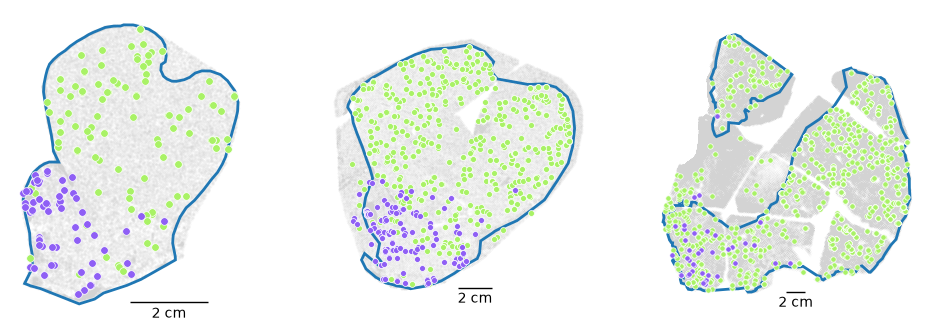

In [8]:
str_chol = ['STRd Cholinergic GABA', 'STR Cholinergic GABA']

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

for i, (species, params) in enumerate(species_params.items()):
    data = params['ad'].obs
    z = params['z_plane']
    subset = data[data['z_order'] == z]
    ax[i].scatter(
        subset[params['xy_cols'][0]],
        subset[params['xy_cols'][1]],
        c='lightgrey',
        **params['bgkwargs'],
    )
    if species == 'marmoset':
        anno_id = subset['brain_section_barcode'].iloc[0]
    else:
        anno_id = f'zpos-{z}'
    _ = get_annotation_coords(anno_id, params['annotations'], annotation='STR', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                    scale_factor=params['scale_factor'], plot_args={'color': '#1f77b4', 'linewidth':2})
    for group in str_chol:
        fg = subset[subset['Group'] == group]
        ax[i].scatter(
            fg[params['xy_cols'][0]],
            fg[params['xy_cols'][1]],
            c=group_color_dict[group],
            **params['fgkwargs'],
        )

    format_spatial_axes(ax[i], invert_y=params['invert_y'])
    

    add_scalebar(ax[i], matchx=False, matchy=False, sizex=2000, labelx='2 cm', offset=(0.5, 0.05), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)

    if save_figs:
        fig.savefig(f'/results/cholinergic.svg', dpi=dpi, bbox_inches='tight', transparent=True)


B. GPin cholinergic cells

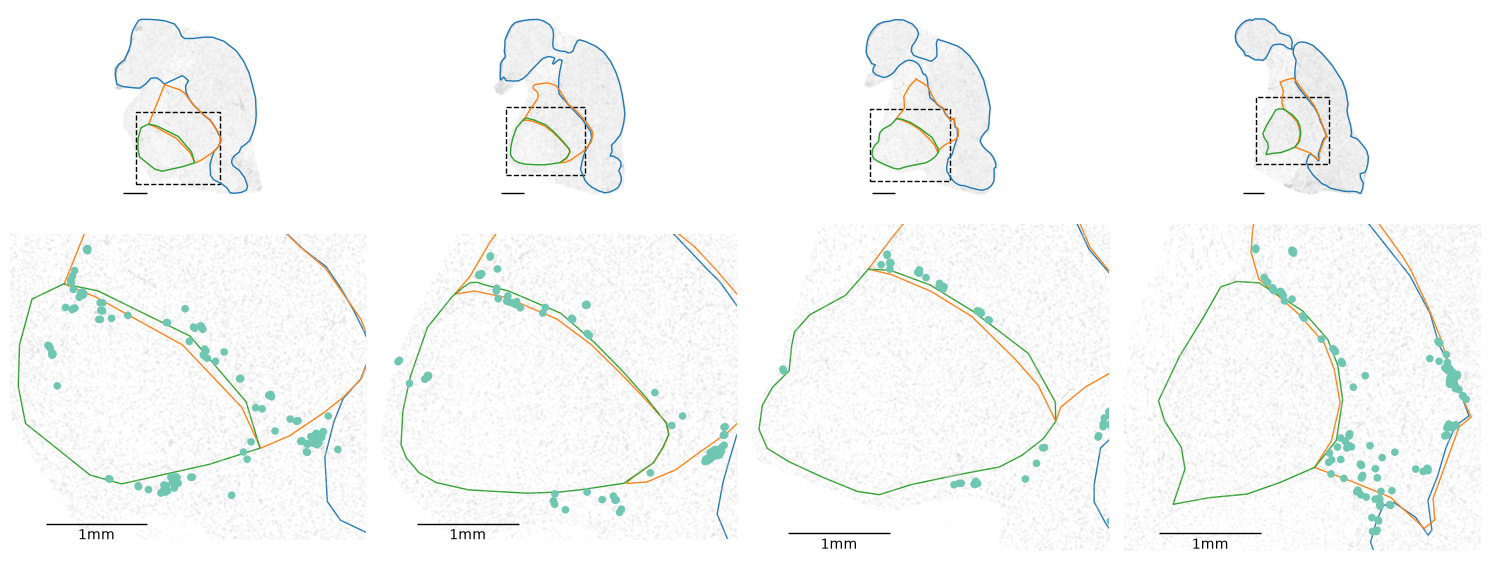

In [9]:
marm_obs = marm_ad.obs
marm_zs = [21, 22, 23, 25]
z_zoom = {
    21:[(2200, 5700), (-10000, -7000)],
    22:[(2200, 5700), (-12000, -9000)],
    23:[(2200, 5700), (-12000, -8800)],
    25:[(3000, 6500), (-11000, -7800)]
}

fig, ax = plt.subplots(
    nrows=2, ncols=len(marm_zs),
    figsize=(15, 6),
    gridspec_kw={'height_ratios': [1, 2]}
)

for i, z in enumerate(marm_zs):
    data = marm_obs[marm_obs['z_order'] == z]
    anno_id = data['brain_section_barcode'].iloc[0]
    ax[0, i].scatter(
        data['x_rotated'],
        data['y_rotated'],
        c='lightgrey',
        rasterized=True,
        s=0.01,
        alpha=0.1,
    )
    format_spatial_axes(ax[0,i], invert_y=False)
    add_scalebar(ax[0, i], matchx=False, matchy=False, sizex=1000, labelx='', offset=(0.1, 0.05), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)

    zoom = z_zoom[z]
    rect = plt.Rectangle(
        (zoom[0][0], zoom[1][0]),
        zoom[0][1] - zoom[0][0],
        zoom[1][1] - zoom[1][0],
        linewidth=1, edgecolor='black', facecolor='none', linestyle='--'
    )
    ax[0, i].add_patch(rect)

    region_palette = plt.get_cmap("tab10")
    regions = ['STR', 'GPe', 'GPi']
    for r, region in enumerate(regions):
        _ = get_annotation_coords(anno_id, marm_transform, annotation=region, ax=ax[0, i], swap_coords=True, rotate_midline=True, 
                                plot_args={'color': region_palette(r), 'linewidth':1})
        _ = get_annotation_coords(anno_id, marm_transform, annotation=region, ax=ax[1, i], swap_coords=True, rotate_midline=True, 
                                plot_args={'color': region_palette(r), 'linewidth':1})
    plot_spatial_subset(
        marm_obs,
        species_params['marmoset']['xy_cols'][0],
        species_params['marmoset']['xy_cols'][1],
        'z_order', 
        z, 
        'Group', 
        ['GPin-BF Cholinergic GABA'], 
        {'s': 20, 'rasterized':True},
        {'s': 1, 'alpha':0.1, 'rasterized':True, 'c':'lightgrey'},
        ax[1, i],
        palette=group_color_dict
    )
    ax[1, i].set_xlim(zoom[0][0], zoom[0][1])
    ax[1, i].set_ylim(zoom[1][0], zoom[1][1])
    add_scalebar(ax[1, i], matchx=False, matchy=False, sizex=1000, labelx='1mm', offset=(0.1, 0.05), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)

plt.tight_layout()

if save_figs:
    fig.savefig(f'/results/gp_chol_marm.svg', dpi=dpi, bbox_inches='tight', transparent=True)

C. Enrichment of oligos

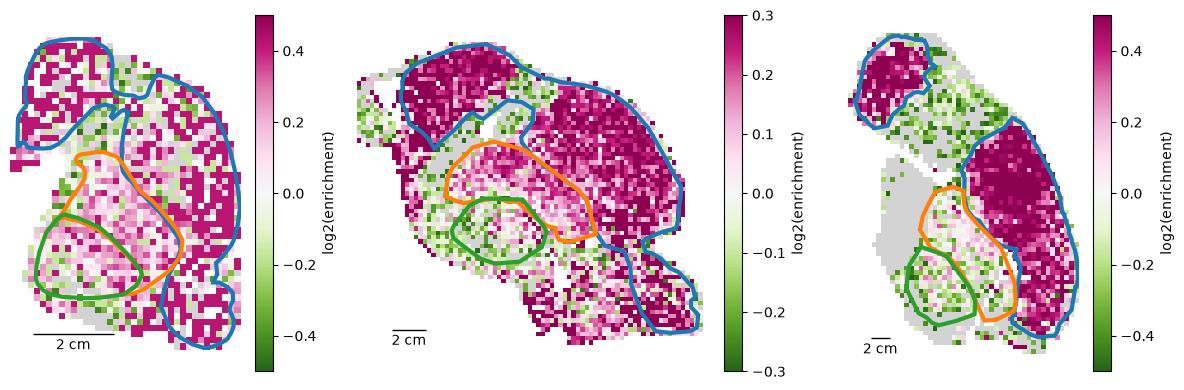

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1.5, 1]})
z_planes = [22, 15, 12]
bin_sizes = [150, 250, 500]
vlims = [(-0.5, 0.5), (-0.3, 0.3), (-0.5, 0.5)]
for i, (species, params) in enumerate(species_params.items()):
    data = params['ad']

    # Calculate the overal proportion of oligos that belon to each Group
    species_oligo = data[data.obs['Group'].isin(['Oligo PLEKHG1', 'Oligo OPALIN'])]
    oligo_proportions_global = species_oligo.obs.groupby('Group', observed=True).size() / species_oligo.shape[0]
    oligo_proportions_global = oligo_proportions_global.to_dict()

    section = species_oligo[species_oligo.obs['z_order'] == z_planes[i]].copy()
    section.obsm['plot_coords'] = section.obs[params['xy_cols']].to_numpy()
    _ = histplot.make_2D_hist_enrichment_log2(
        section,
        obs_field='Group',
        category='Oligo OPALIN',  # None to get total counts
        coords_obsm_key='plot_coords',
        binsize=bin_sizes[i],
        imshow_size=None,
        global_propor_dict=oligo_proportions_global,
        vlims=vlims[i],
        cmap='PiYG_r',
        no_cells_color="white",  # bins with no cells
        no_category_color="lightgrey",  # bins with cells but no category
        show_colorbar=True,  # only last panel in each row
        ax=ax[i],
    )
    ax[i].legend_.remove()
    ax[i].images[0].set_rasterized(True)
    ax[i].set_title('')

    if species == 'marmoset':
        anno_id = section.obs['brain_section_barcode'].iloc[0]
    else:
        anno_id = f'zpos-{z_planes[i]}'
    region_palette = plt.get_cmap("tab10")
    regions = ['STR', 'GPe', 'GPi']
    for r, region in enumerate(regions):
        _ = get_annotation_coords(
            anno_id,
            params['annotations'],
            annotation=region,
            ax=ax[i],
            swap_coords=True,
            rotate_midline=params['rotate_midline'],
            scale_factor=params['scale_factor'],
            plot_args={'color': region_palette(r), 'linewidth': 3},
        )
    if params['invert_y']:
        ax[i].invert_yaxis() 
    add_scalebar(ax[i], matchx=False, matchy=False, sizex=2000, labelx='2 cm', offset=(0.1, 0.05), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)

plt.tight_layout()

if save_figs:
    fig.savefig(f'/results/oligo_enrichment.svg', dpi=dpi, bbox_inches='tight', transparent=True)

D. Enrichement of astrocyte clusters in macaque

In [11]:
mac_astro = mac_ad[mac_ad.obs['Group'] == 'Astrocyte']

In [12]:
# Calculate the overal proportion of astrocytes that belong to each astrocyte cluster
astro_cluster_proportions_global = mac_astro.obs.groupby('Cluster', observed=True).size() / mac_astro.shape[0]
astro_cluster_proportions_global = astro_cluster_proportions_global.to_dict()
astro_prop_df = pd.DataFrame([astro_cluster_proportions_global], index=["Global"]).T
astro_prop_df = astro_prop_df.sort_values(by="Global", ascending=False).T
astro_prop_df

,Macaque-257,Macaque-231,Macaque-232,Macaque-233,Macaque-234,Macaque-236,Macaque-235
Global,0.412161,0.256086,0.24847,0.063832,0.010854,0.008509,0.000087


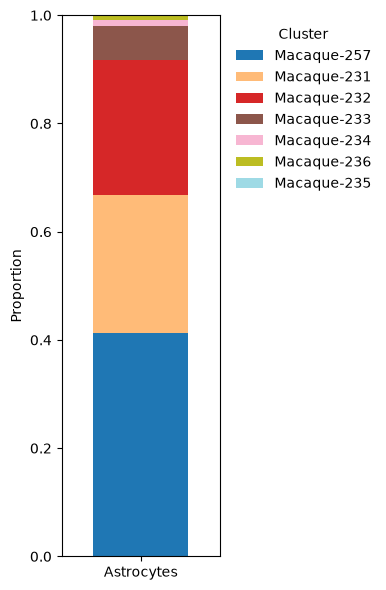

In [13]:
color_list = plt.cm.tab20(np.linspace(0, 1, astro_prop_df.shape[1]))

fig, ax = plt.subplots(figsize=(4, 6))
astro_prop_df.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=color_list,
    width=0.75,
    edgecolor="none",
)

ax.set_xticklabels(["Astrocytes"], rotation=0)
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1)
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

if save_figs is True:
    fig.savefig(f'/results/mac_astro_prop.svg', bbox_inches='tight', transparent=False)

no GPe feature for section zpos-5
no GPi feature for section zpos-5
no SN feature for section zpos-5
no STH feature for section zpos-5
no GPe feature for section zpos-7
no GPi feature for section zpos-7
no SN feature for section zpos-7
no STH feature for section zpos-7
no GPi feature for section zpos-14
no SN feature for section zpos-14
no STH feature for section zpos-14
no SN feature for section zpos-15
no STH feature for section zpos-15
no GPe feature for section zpos-5
no GPi feature for section zpos-5
no SN feature for section zpos-5
no STH feature for section zpos-5
no GPe feature for section zpos-7
no GPi feature for section zpos-7
no SN feature for section zpos-7
no STH feature for section zpos-7
no GPi feature for section zpos-14
no SN feature for section zpos-14
no STH feature for section zpos-14
no SN feature for section zpos-15
no STH feature for section zpos-15
no GPe feature for section zpos-5
no GPi feature for section zpos-5
no SN feature for section zpos-5
no STH featur

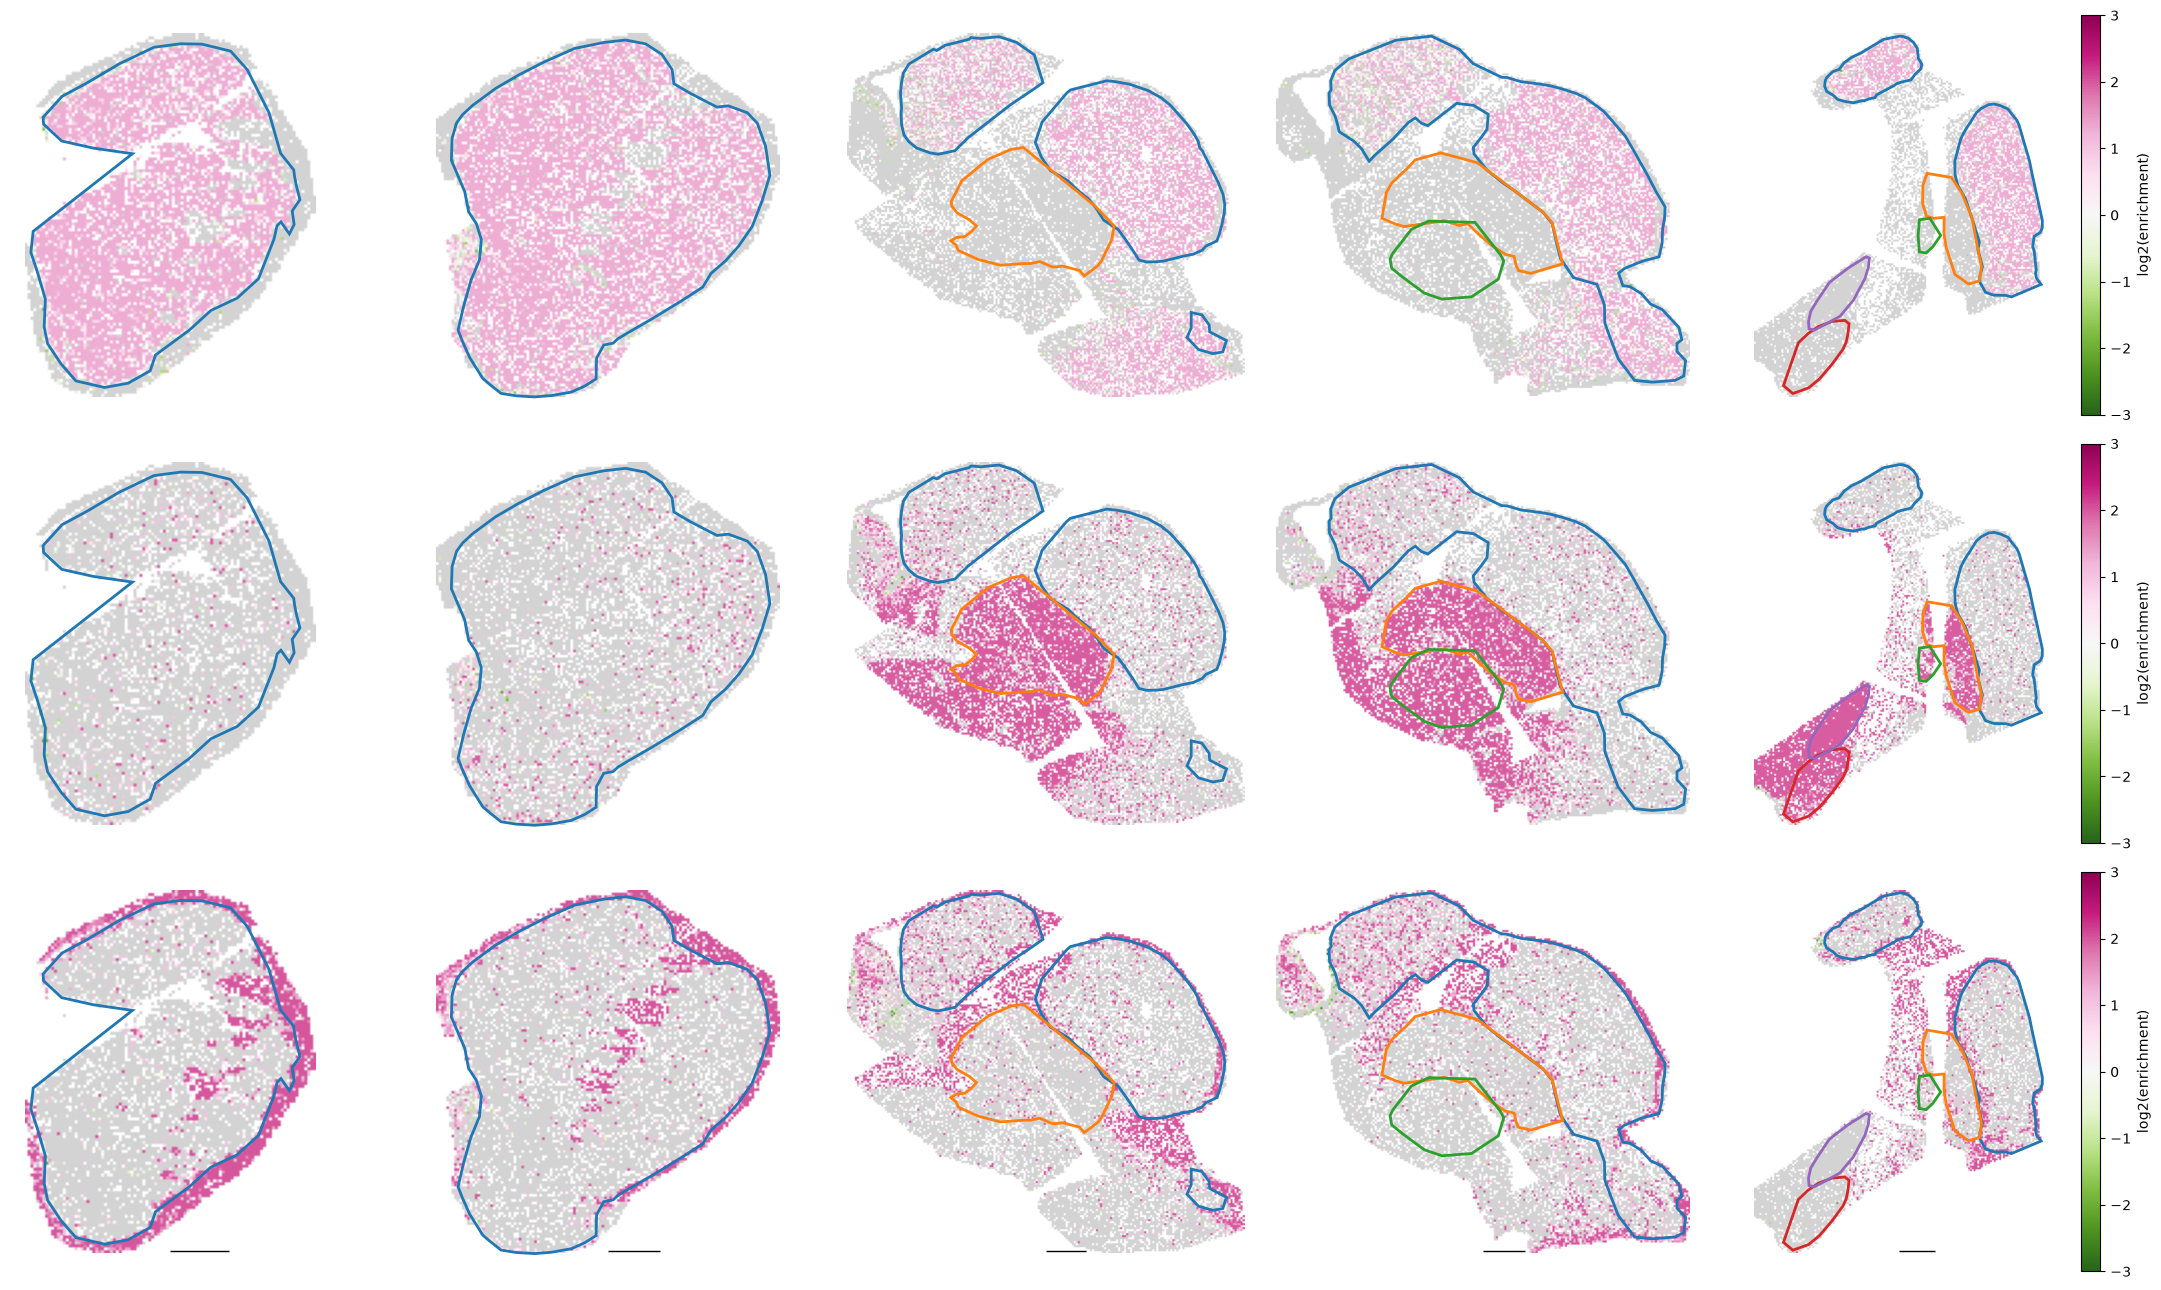

In [14]:
sections = [5, 7, 14, 15, 20]
fig, axes = plt.subplots(3, len(sections), figsize=(4.5 * len(sections), 13))
obs_field = 'Cluster'
astro_clusters = ["Macaque-257", "Macaque-231", "Macaque-232"]
zoom_pad_frac = 0.05  # 5% margin around data bounds

for j, cluster in enumerate(astro_clusters):

    for i, sec in enumerate(sections):
        ax = axes[j, i]
        adata_sec = mac_astro[mac_astro.obs['z_order'] == sec].copy()
        adata_sec.obsm['plot_coords'] = adata_sec.obs[['x_slab_um', 'y_slab_um']].to_numpy()

        _ = histplot.make_2D_hist_enrichment_log2(
            adata_sec,
            obs_field=obs_field,
            category=cluster,  # None to get total counts
            coords_obsm_key='plot_coords',
            binsize=100,
            imshow_size=None,
            global_propor_dict=astro_cluster_proportions_global,
            vlims=(-3, 3),
            cmap='PiYG_r',
            no_cells_color="white",  # bins with no cells
            no_category_color="lightgrey",  # bins with cells but no category
            show_colorbar=(i == len(sections) - 1),  # only last panel in each row
            ax=ax,
        )
        ax.images[0].set_rasterized(True)
        ax.set_title('')

        region_palette = plt.get_cmap("tab10")
        regions = ['STR', 'GPe', 'GPi', 'SN', 'STH']
        for r, region in enumerate(regions):
            _ = get_annotation_coords(
                f'zpos-{sec}',
                mac_transform,
                annotation=region,
                ax=ax,
                swap_coords=True,
                rotate_midline=False,
                scale_factor=20,
                plot_args={'color': region_palette(r), 'linewidth': 2},
            )
        
        # Zoom to occupied spatial region for this section
        xy = adata_sec.obsm['plot_coords']
        x_min, x_max = np.nanmin(xy[:, 0]), np.nanmax(xy[:, 0])
        y_min, y_max = np.nanmin(xy[:, 1]), np.nanmax(xy[:, 1])
        dx = (x_max - x_min) * zoom_pad_frac
        dy = (y_max - y_min) * zoom_pad_frac
        ax.set_xlim(x_min - dx, x_max + dx)
        ax.set_ylim(y_min - dy, y_max + dy)

        ax.invert_yaxis()  # Invert y-axis for proper orientation

        add_scalebar(
            ax=axes[2, i], matchx=False, matchy=False,
            sizex=2000, labelx='', offset=(0.5, 0.05),
            hidex=True, hidey=True, loc='lower left', barwidth=1
)

        # Remove any legend if one is created internally
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()

    plt.subplots_adjust(hspace=0.35, wspace=0.05)


plt.tight_layout()
plt.show()
if save_figs is True:
    fig.savefig(f'/results/mac_astro_enrichment.svg', bbox_inches='tight', transparent=False)